In [2]:
import pandas as pd
import numpy as np

# Kiểm tra các file hiện có
print("Danh sách các file trong thư mục:")
!ls *.csv

Danh sách các file trong thư mục:
gia_nha.csv  hai_vang_trang.csv  sinh_vien_mo_rong.csv


In [3]:
import numpy as np

# Ba bạn: A và C học gần như y hệt nhau, B học khác hẳn
ba_ban = {
    "A": np.array([5.0, 3.0, 4000.0]),
    "B": np.array([25.0, 9.0, 4100.0]),
    "C": np.array([6.0, 3.5, 7000.0]),
}

def kc(u, v):
    """Khoang cach Euclid giua hai diem."""
    return np.sqrt(((u - v) ** 2).sum())

print("Khoang cach KHI CHUA chuan hoa:")
print(f"d(A, B) = {kc(ba_ban['A'], ba_ban['B']):8.1f}")
print(f"d(A, C) = {kc(ba_ban['A'], ba_ban['C']):8.1f}")

Khoang cach KHI CHUA chuan hoa:
d(A, B) =    102.2
d(A, C) =   3000.0


In [5]:
import pandas as pd

df = pd.read_csv("sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]].to_numpy(dtype=float)

tb = X.mean(axis=0)
dl = X.std(axis=0)

print("Do lech chuan cua ba cot:")
print(f"gio_on {dl[0]:.2f} | diem_giua_ky {dl[1]:.2f} | chi_tieu {dl[2]:.0f}")

chuan = {ten: (v - tb) / dl for ten, v in ba_ban.items()}
print("\nKhoang cach SAU KHI chuan hoa:")
print(f"d(A, B) = {kc(chuan['A'], chuan['B']):.2f}")
print(f"d(A, C) = {kc(chuan['A'], chuan['C']):.2f}")

Do lech chuan cua ba cot:
gio_on 7.82 | diem_giua_ky 2.09 | chi_tieu 1692

Khoang cach SAU KHI chuan hoa:
d(A, B) = 3.85
d(A, C) = 1.79


In [6]:
X2 = df[["gio_on", "diem_giua_ky"]].to_numpy(dtype=float)
y = df["qua_mon"].to_numpy()
tb2, dl2 = X2.mean(axis=0), X2.std(axis=0)

ban_moi = np.array([12.0, 6.5])
X2c = (X2 - tb2) / dl2
moi_c = (ban_moi - tb2) / dl2

khoang = np.sqrt(((X2c - moi_c) ** 2).sum(axis=1))
gan = np.argsort(khoang)[:5]

print("Ban moi: on 12 gio, diem giua ky 6.5")
print("Nam lang gieng gan nhat:")
for i in gan:
    ket = "qua" if y[i] == 1 else "rot"
    print(f"  gio {X2[i, 0]:5.1f} | diem {X2[i, 1]:4.1f} | khoang cach {khoang[i]:.3f} -> {ket}")

so_qua = int(y[gan].sum())
print(f"\nBo phieu: {so_qua} qua, {5 - so_qua} rot")
print("Du doan:", "qua mon" if so_qua >= 3 else "rot mon")

Ban moi: on 12 gio, diem giua ky 6.5
Nam lang gieng gan nhat:
  gio  10.5 | diem  6.4 | khoang cach 0.198 -> qua
  gio  12.5 | diem  6.1 | khoang cach 0.202 -> qua
  gio  14.0 | diem  6.4 | khoang cach 0.260 -> qua
  gio   9.5 | diem  6.1 | khoang cach 0.373 -> rot
  gio  10.5 | diem  5.8 | khoang cach 0.386 -> qua

Bo phieu: 4 qua, 1 rot
Du doan: qua mon


In [7]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_mo_rong.csv")
y = df["qua_mon"]
X3 = df[["gio_on", "diem_giua_ky", "chi_tieu"]]

X_tr, X_te, y_tr, y_te = train_test_split(
    X3, y, test_size=0.25, random_state=17, stratify=y
)

def cham(mo_hinh, cot):
    mo_hinh.fit(X_tr[cot], y_tr)
    return accuracy_score(y_te, mo_hinh.predict(X_te[cot]))

def knn_chuan():
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))

ba_cot = ["gio_on", "diem_giua_ky", "chi_tieu"]
hai_cot = ["gio_on", "diem_giua_ky"]

a = cham(KNeighborsClassifier(n_neighbors=7), ba_cot)
b = cham(knn_chuan(), ba_cot)
c = cham(knn_chuan(), hai_cot)

print(f"Doan bua ca lop qua          : {y_te.mean():.4f}")
print(f"Ba cot, khong chuan hoa      : {a:.4f}")
print(f"Ba cot, co chuan hoa         : {b:.4f}")
print(f"Bo cot chi_tieu, co chuan hoa: {c:.4f}")

Doan bua ca lop qua          : 0.6000
Ba cot, khong chuan hoa      : 0.5333
Ba cot, co chuan hoa         : 0.8667
Bo cot chi_tieu, co chuan hoa: 0.9000


In [8]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Kiem dinh cheo 5 phan tren tap hoc:")
diem = {}
for k in range(1, 52, 2):
    diem[k] = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_tr, y_tr, cv=5).mean()

k_tot = max(diem, key=diem.get)

for k in [1, 5, 9, 13, 17, 25, 51]:
    dau = " <- tot nhat" if k == k_tot else ""
    print(f"k = {k:2d} | diem trung binh {diem[k]:.4f}{dau}")

mh = KNeighborsClassifier(n_neighbors=k_tot).fit(X_tr, y_tr)
print(f"\nk tot nhat = {k_tot}")
acc = accuracy_score(y_te, mh.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Kiem dinh cheo 5 phan tren tap hoc:
k =  1 | diem trung binh 0.7778
k =  5 | diem trung binh 0.8444
k =  9 | diem trung binh 0.8444
k = 13 | diem trung binh 0.8667 <- tot nhat
k = 17 | diem trung binh 0.8533
k = 25 | diem trung binh 0.8622
k = 51 | diem trung binh 0.8533

k tot nhat = 13
Accuracy tren tap kiem tra = 0.9200


In [9]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cac_mo_hinh = [
    ("Hoi quy logistic", LogisticRegression()),
    ("Naive Bayes     ", GaussianNB()),
    ("KNN, k = 13     ", KNeighborsClassifier(n_neighbors=13)),
]

print("Accuracy tren tap kiem tra, bo hai vang trang:")
for ten, mh in cac_mo_hinh:
    mh.fit(X_tr, y_tr)
    print(f"{ten}: {accuracy_score(y_te, mh.predict(X_te)):.4f}")

Accuracy tren tap kiem tra, bo hai vang trang:
Hoi quy logistic: 0.8533
Naive Bayes     : 0.8533
KNN, k = 13     : 0.9200


In [10]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

knn = KNeighborsRegressor(n_neighbors=5).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print("MAE tren tap kiem tra (ty dong):")
mae_knn = mean_absolute_error(y_te, knn.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"KNN, k = 5  : {mae_knn:.4f}")
print(f"Duong thang : {mae_duong:.4f}")

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("\nDu doan cho bon can moi (ty dong):")
print("dien tich |  KNN  | duong thang")
for dt, a, b in zip(can_moi["dien_tich"], knn.predict(can_moi), duong.predict(can_moi)):
    print(f"  {dt:6.0f} m2 | {a:5.2f} |    {b:5.2f}")

MAE tren tap kiem tra (ty dong):
KNN, k = 5  : 0.4030
Duong thang : 0.2578

Du doan cho bon can moi (ty dong):
dien tich |  KNN  | duong thang
      60 m2 |  4.95 |     5.12
     100 m2 |  8.32 |     8.24
     150 m2 |  9.32 |    12.13
     250 m2 |  9.32 |    19.91


/tmp/ipykernel_1041/3986380507.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


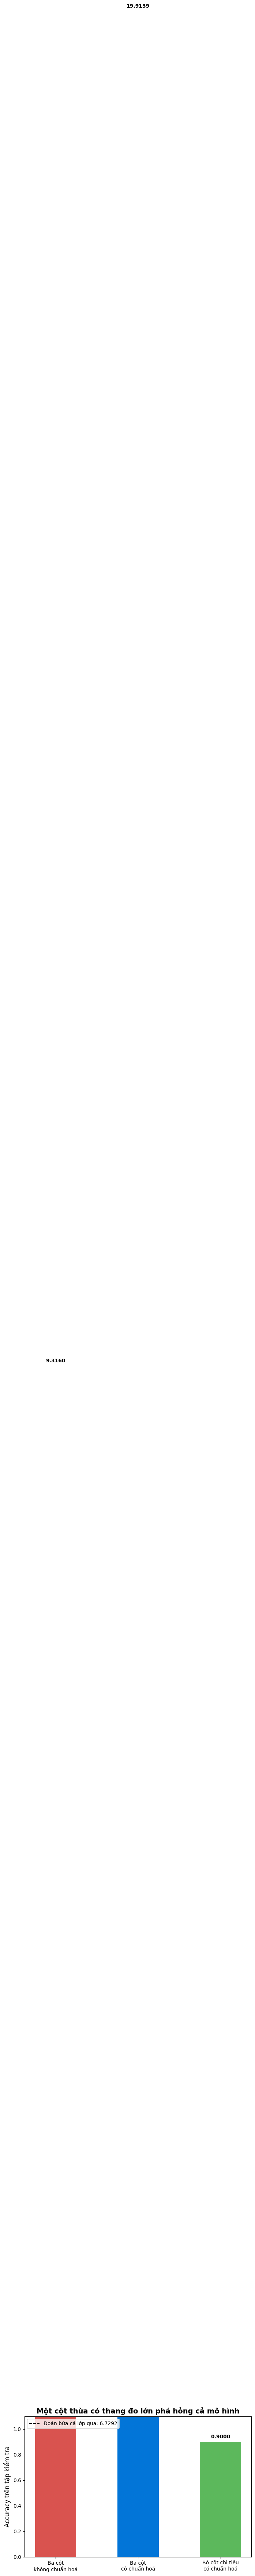

In [11]:
import matplotlib.pyplot as plt

categories = ['Ba cột\nkhông chuẩn hoá', 'Ba cột\ncó chuẩn hoá', 'Bỏ cột chi tiêu\ncó chuẩn hoá']
values = [a, b, c]
colors = ['#d9534f', '#0275d8', '#5cb85c']

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(categories, values, color=colors, width=0.5)
ax.axhline(y=y_te.mean(), color='black', linestyle='--', label=f'Đoán bừa cả lớp qua: {y_te.mean():.4f}')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')

ax.set_ylabel('Accuracy trên tập kiểm tra', fontsize=12)
ax.set_ylim(0, 1.1)
ax.set_title('Một cột thừa có thang đo lớn phá hỏng cả mô hình', fontsize=14, fontweight='bold')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

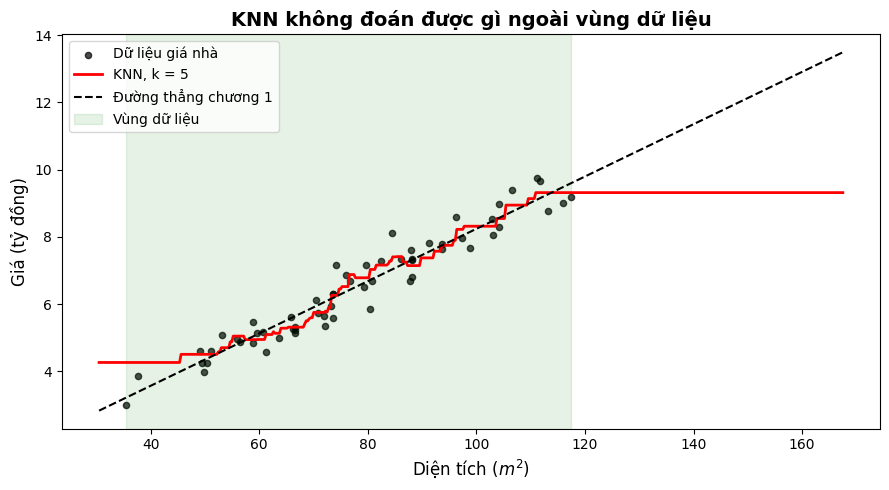

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

df_gh = pd.read_csv("gia_nha.csv")
X_gh = df_gh[["dien_tich"]]
y_gh = df_gh["gia"]
X_tr_gh, X_te_gh, y_tr_gh, y_te_gh = train_test_split(X_gh, y_gh, test_size=0.2, random_state=42)

knn_reg = KNeighborsRegressor(n_neighbors=5).fit(X_tr_gh, y_tr_gh)
lin_reg = LinearRegression().fit(X_tr_gh, y_tr_gh)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X_gh["dien_tich"], y_gh, color='black', s=20, label='Dữ liệu giá nhà', alpha=0.7)

X_plot = np.linspace(X_gh["dien_tich"].min() - 5, X_gh["dien_tich"].max() + 50, 500).reshape(-1, 1)
X_plot_df = pd.DataFrame(X_plot, columns=["dien_tich"])

ax.plot(X_plot, knn_reg.predict(X_plot_df), color='red', label='KNN, k = 5', linewidth=2)
ax.plot(X_plot, lin_reg.predict(X_plot_df), color='black', linestyle='--', label='Đường thẳng chương 1', linewidth=1.5)

ax.axvspan(X_gh["dien_tich"].min(), X_gh["dien_tich"].max(), color='green', alpha=0.1, label='Vùng dữ liệu')

ax.set_xlabel('Diện tích ($m^2$)', fontsize=12)
ax.set_ylabel('Giá (tỷ đồng)', fontsize=12)
ax.set_title('KNN không đoán được gì ngoài vùng dữ liệu', fontsize=14, fontweight='bold')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()